# Decision Tree Regression – California Housing Dataset

**Objective:** Predict the median house value (`target`) using eight numeric housing and geographic features.

This notebook follows Parts A–J of the assignment. Run the cells from top to bottom. Keep `california_housing.csv` in the same folder as this notebook.

**Reproducibility:** `test_size=0.20`, `random_state=42`.

## Part A – Conceptual Questions

1. **What is a Decision Tree Regressor?**  
   It is a supervised machine-learning algorithm that predicts a continuous numerical value by repeatedly splitting the feature space into smaller groups. Each terminal leaf predicts a value based on the training observations in that leaf.

2. **How does a regression tree choose a split?**  
   With `criterion="squared_error"`, it selects the feature and threshold that produce the greatest reduction in the weighted mean squared error (variance/impurity) of the child nodes.

3. **Why is feature scaling generally unnecessary?**  
   A decision tree makes threshold-based splits on one feature at a time. Scaling a feature with a monotonic transformation generally preserves the ordering of its values and does not require features to share a common scale.

4. **Why can a decision tree overfit?**  
   A deep tree can keep splitting until it learns very small groups or individual training observations, capturing noise as well as genuine patterns.

5. **What does `max_depth` control?**  
   It limits the maximum number of levels in the tree. A smaller depth creates a simpler model; an unrestricted tree can become very complex.

6. **Explain bias and variance.**  
   High bias means the model is too simple and misses important patterns (underfitting). High variance means the model is too sensitive to the training data (overfitting). The goal is to balance both for good performance on unseen data.

## Part B – Explore the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Mohithshv\Desktop\PROJECTS\Decision_Tree_Regression_California_Housing\california_housing.csv")

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
display(df.describe().T)

target_column = "target"
feature_columns = [column for column in df.columns if column != target_column]

print("Target:", target_column)
print("Features:", feature_columns)

Dataset shape: (20640, 9)

Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'target']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422



Missing values:


,missing_count
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
target,0



Data types:


,dtype
MedInc,float64
HouseAge,int64
AveRooms,float64
AveBedrms,float64
Population,int64
AveOccup,float64
Latitude,float64
Longitude,float64
target,float64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
target,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Target: target
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


### Part B – Target distribution

The histogram below shows the distribution of the target variable. A concentration at the upper end can occur because the California Housing target values are capped in the original dataset.

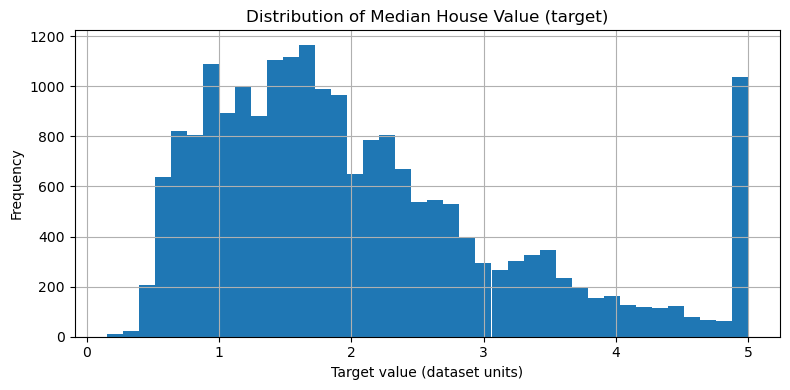

In [2]:
df[target_column].hist(bins=40, figsize=(8, 4))
plt.title("Distribution of Median House Value (target)")
plt.xlabel("Target value (dataset units)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Part C – Prepare the Data and Split

In [3]:
from sklearn.model_selection import train_test_split

# The supplied dataset has no missing values. This check makes that assumption explicit.
if df.isna().any().any():
    df = df.dropna().copy()

X = df[feature_columns]
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (16512, 8)
Testing feature shape: (4128, 8)
Training target shape: (16512,)
Testing target shape: (4128,)


## Part D – Train the Baseline Decision Tree Regressor

In [4]:
from sklearn.tree import DecisionTreeRegressor

baseline_model = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=42
)
baseline_model.fit(X_train, y_train)

train_predictions = baseline_model.predict(X_train)
test_predictions = baseline_model.predict(X_test)
print("Baseline model trained.")

Baseline model trained.


## Part E – Evaluate the Baseline Model

In [5]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def regression_metrics(model, X_train, y_train, X_test, y_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {
        "Training R2": r2_score(y_train, train_pred),
        "Testing R2": r2_score(y_test, test_pred),
        "MAE": mean_absolute_error(y_test, test_pred),
        "RMSE": mean_squared_error(y_test, test_pred) ** 0.5
    }

baseline_results = regression_metrics(
    baseline_model, X_train, y_train, X_test, y_test
)
display(pd.Series(baseline_results, name="Baseline result").to_frame())

,Baseline result
Training R2,1.000000
Testing R2,0.622076
MAE,0.454679
RMSE,0.703729


### Interpretation

- **R²:** The proportion of target variation explained by the model. A value closer to 1 indicates stronger predictive fit.
- **MAE:** The average absolute difference between actual and predicted values, in target units.
- **RMSE:** The square root of average squared prediction error. It penalizes larger errors more strongly than MAE.
- If training R² is much higher than testing R², the model is likely overfitting.

## Part F – Compare `max_depth` Values

In [6]:
depth_results = []
depth_models = {}

for depth in [3, 7, None]:
    model = DecisionTreeRegressor(
        criterion="squared_error",
        random_state=42,
        max_depth=depth
    )
    model.fit(X_train, y_train)
    depth_models[depth] = model
    metrics = regression_metrics(model, X_train, y_train, X_test, y_test)
    depth_results.append({"max_depth": str(depth), **metrics})

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df)

,max_depth,Training R2,Testing R2,MAE,RMSE
0,3,0.537898,0.509763,0.597828,0.801505
1,7,0.716698,0.651570,0.473161,0.675711
2,None,1.000000,0.622076,0.454679,0.703729


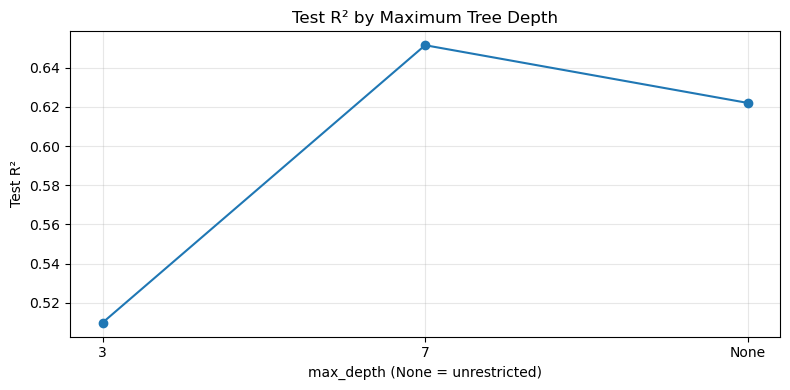

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(depth_results_df["max_depth"], depth_results_df["Testing R2"], marker="o")
plt.title("Test R² by Maximum Tree Depth")
plt.xlabel("max_depth (None = unrestricted)")
plt.ylabel("Test R²")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Part F – Interpretation

A shallow tree (`max_depth=3`) may underfit because it cannot represent enough patterns. An unrestricted tree can fit the training data extremely closely and may overfit. Compare the training and testing R² values to assess this trade-off.

## Part G – Visualize a Decision Tree

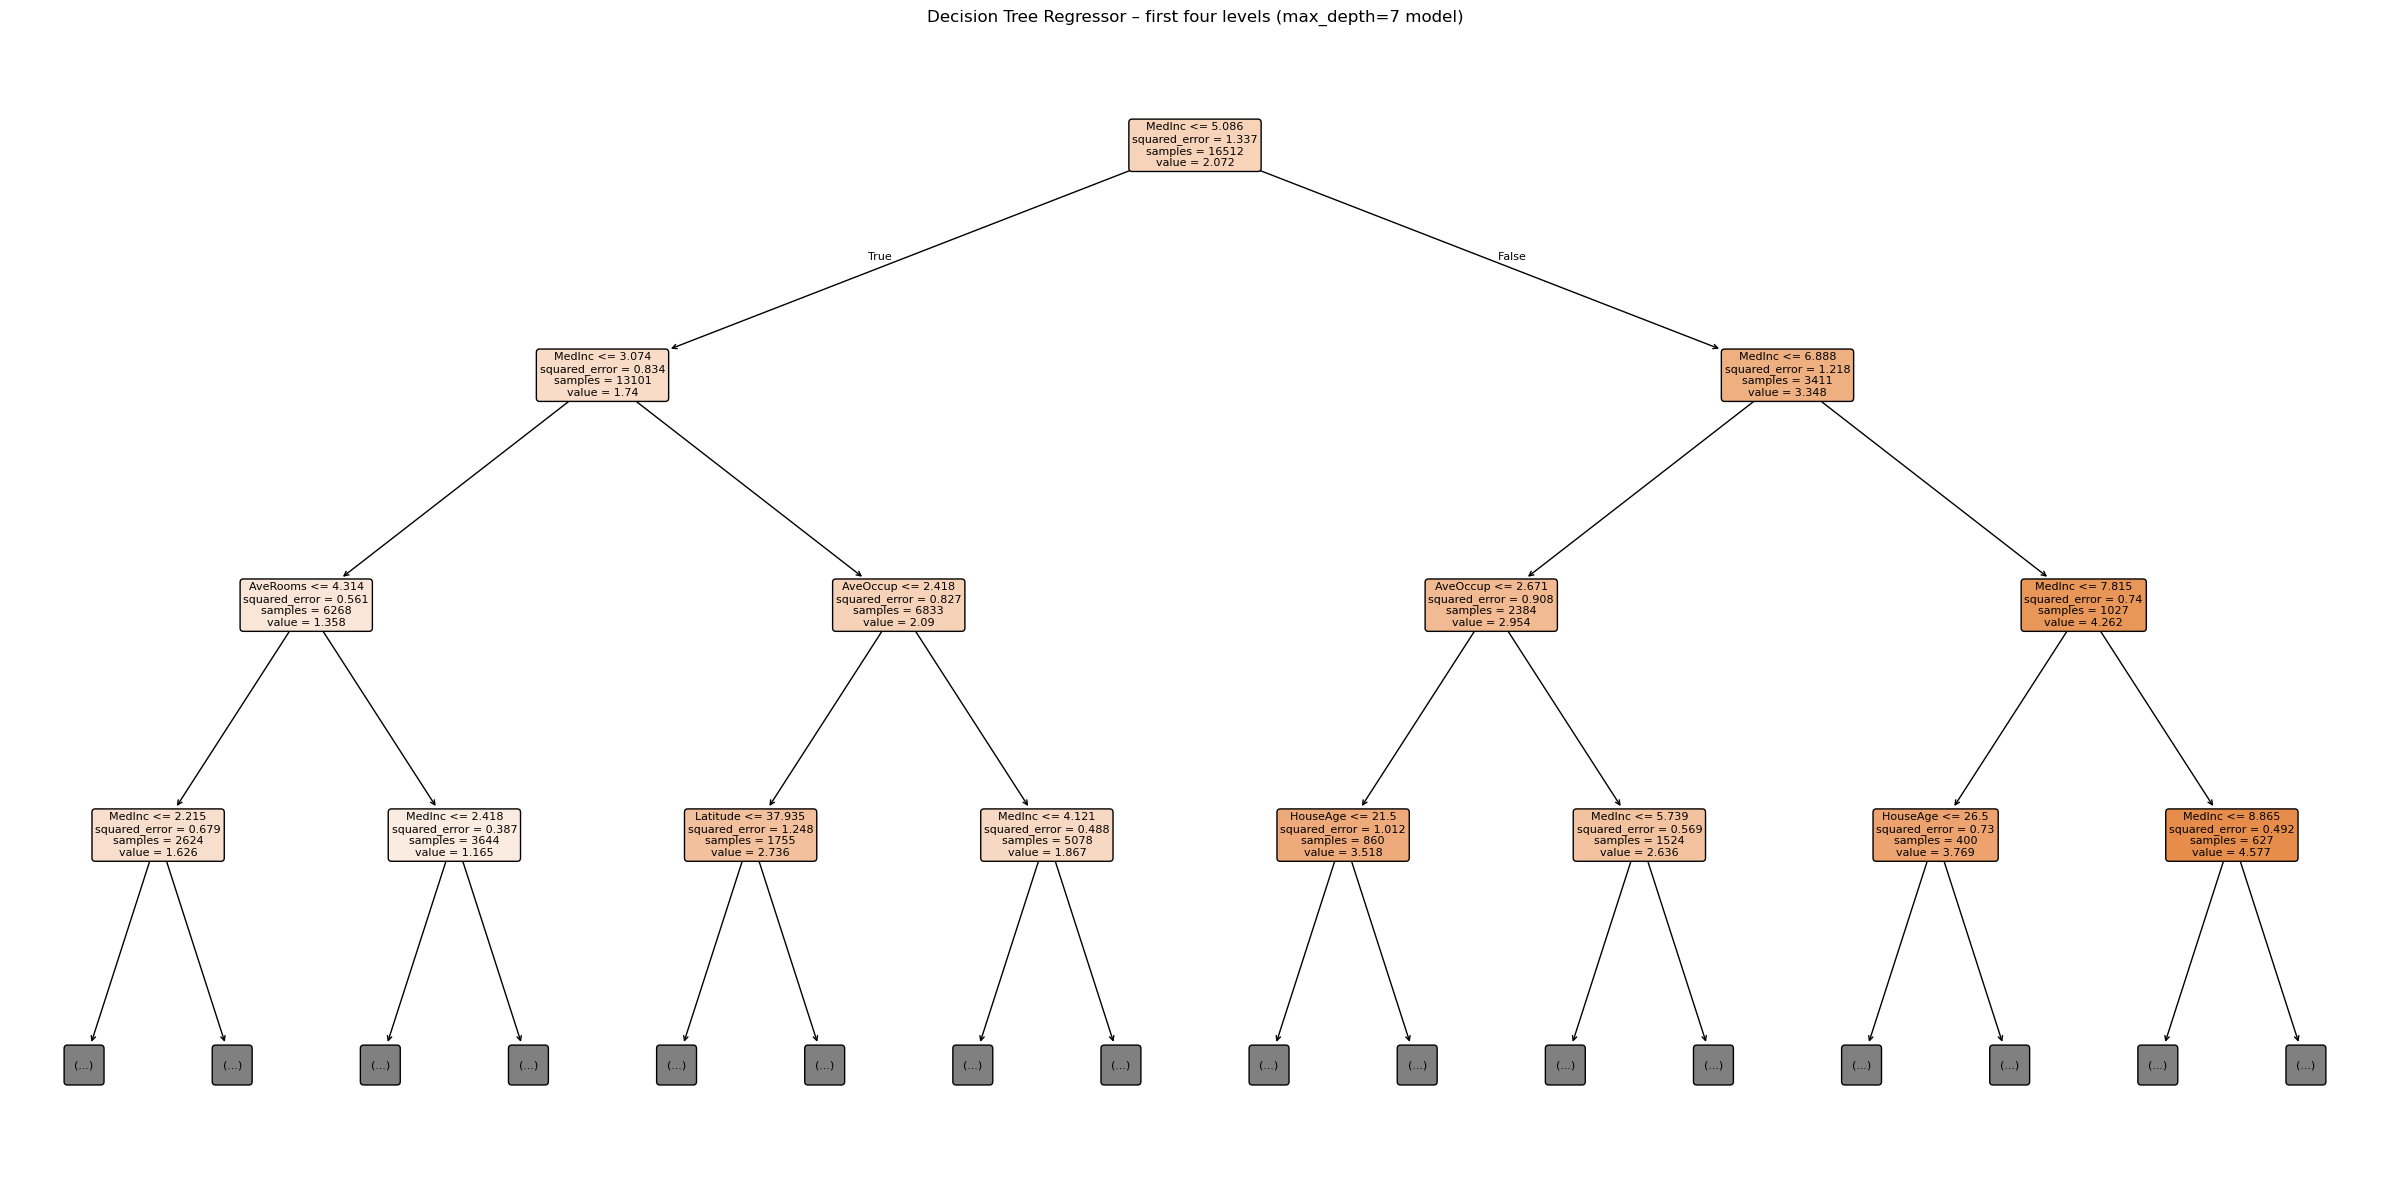

In [8]:
from sklearn.tree import plot_tree

# Visualize the max_depth=7 model so the full tree remains readable.
tree_for_plot = depth_models[7]

plt.figure(figsize=(24, 12))
plot_tree(
    tree_for_plot,
    feature_names=feature_columns,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree Regressor – first four levels (max_depth=7 model)")
plt.tight_layout()
plt.show()

**How to read the tree:** Each internal node displays a feature threshold. Observations satisfying the condition follow the left branch (`True`); the others follow the right branch (`False`). `samples` is the number of training rows at that node, and `value` is the predicted mean target for the node. Grey boxes marked `...` indicate branches hidden by the display limit, not missing model data.

## Part H – Compare Splitting Criteria and `min_samples_leaf`

In [9]:
criterion_results = []
criterion_models = {}

for criterion in ["squared_error", "absolute_error"]:
    model = DecisionTreeRegressor(
        criterion=criterion,
        random_state=42,
        max_depth=7
    )
    model.fit(X_train, y_train)
    criterion_models[criterion] = model
    metrics = regression_metrics(model, X_train, y_train, X_test, y_test)
    criterion_results.append({"criterion": criterion, **metrics})

criterion_results_df = pd.DataFrame(criterion_results)
display(criterion_results_df)

,criterion,Training R2,Testing R2,MAE,RMSE
0,squared_error,0.716698,0.651570,0.473161,0.675711
1,absolute_error,0.684779,0.625919,0.472505,0.700142


In [ ]:
leaf_results = []
leaf_models = {}

for leaf in [1, 5, 10, 20, 50]:
    model = DecisionTreeRegressor(
        criterion="squared_error",
        random_state=42,
        max_depth=None,
        min_samples_leaf=leaf
    )
    model.fit(X_train, y_train)
    leaf_models[leaf] = model
    metrics = regression_metrics(model, X_train, y_train, X_test, y_test)
    leaf_results.append({"min_samples_leaf": leaf, **metrics})

leaf_results_df = pd.DataFrame(leaf_results)
display(leaf_results_df)

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(leaf_results_df["min_samples_leaf"], leaf_results_df["Testing R2"], marker="o")
plt.title("Test R² by min_samples_leaf")
plt.xlabel("min_samples_leaf")
plt.ylabel("Test R²")
plt.xticks([1, 5, 10, 20, 50])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Important methodology note:** The highest test R² among the manually tried leaf sizes is useful for reproducing this assignment's experiment, but choosing hyperparameters directly on the test set leaks information from the test set into model selection. For a rigorous workflow, use cross-validation on the training set to choose hyperparameters and reserve the test set for one final evaluation.

## Part I – Select the Best Tested Model and Inspect Predictions

In [ ]:
best_leaf_row = leaf_results_df.loc[leaf_results_df["Testing R2"].idxmax()]
best_leaf = int(best_leaf_row["min_samples_leaf"])
best_model = leaf_models[best_leaf]
best_test_predictions = best_model.predict(X_test)

print("Best leaf size among the tested values:", best_leaf)
display(best_leaf_row.to_frame("Best tested model"))

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_test_predictions, alpha=0.35)
low = min(y_test.min(), best_test_predictions.min())
high = max(y_test.max(), best_test_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.title(f"Actual vs Predicted (min_samples_leaf={best_leaf})")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.tight_layout()
plt.show()

### Reflection

- Decision trees are easy to interpret and can model nonlinear relationships without feature scaling.
- A single tree can be unstable and may overfit.
- Housing prices are influenced by factors that may not be present in this dataset, so predictions have limitations.
- Ensemble methods such as Random Forest and Gradient Boosting often improve predictive performance by combining multiple trees.

## Part J – Conclusion

In [ ]:
print(
    f"Conclusion: Among the tested min_samples_leaf values, {best_leaf} "
    f"gave the highest test R² ({best_leaf_row['Testing R2']:.4f})."
)
print(
    "Report MAE and RMSE alongside R² because they describe prediction error "
    "in the target variable's units."
)

## Optional – Save the Best Tested Model and Results

Run this cell if you want to save the model and experiment tables in the notebook's folder.

In [ ]:
import json
import pickle

model_path = "best_decision_tree.pkl"
with open(model_path, "wb") as file:
    pickle.dump(best_model, file)

results_summary = {
    "best_min_samples_leaf_tested": best_leaf,
    "best_model_metrics": {
        key: float(value) for key, value in regression_metrics(
            best_model, X_train, y_train, X_test, y_test
        ).items()
    },
    "selection_note": (
        "Selected by highest test R2 among manually tested values. "
        "Use training-set cross-validation for unbiased hyperparameter selection."
    )
}
with open("results_summary.json", "w") as file:
    json.dump(results_summary, file, indent=2)

print("Saved:", model_path, "and results_summary.json")